# NB2 — Auditoría de la telemetría de una corrida

Este cuaderno abre **una corrida** de la v4 y explica, paso a paso, qué registra el sistema por ciclo y cómo de esos registros salen las cifras del `summary.json` que usa el análisis estadístico (NB1). Es el equivalente en Python del visor `<corrida>.viewer.html`, con acceso a todos los campos.

| Sección | Qué muestra |
|---|---|
| §1 | Los archivos de una corrida y las columnas del CSV por grupo |
| §2 | Del registro por ciclo al `summary.json`: cada métrica recalculada y verificada |
| §3 | El ritmo del lazo: período entre ciclos y latencia del grafo |
| §4 | La traza de decisión: ruta activa, waypoint y distancia al objetivo |
| §5 | El `ObstacleField` en el tiempo: fuente de evidencia, TTC y bloqueo por sector |
| §6 | La capa estratégica: consultas, respuesta por sector y sub-metas |
| §7 | Atascos y gobernador de velocidad |
| §8 | La trayectoria sobre el mapa cenital registrado, con el plan de ruta y la distancia mínima |
| §9 | Desglose por waypoint |
| §10 | La misma semilla volada por los cuatro brazos |

**Cómo usar:** cambiar `RUN_DIR` en §0 por cualquier corrida de `airsim-runs/produccion/v4/` y ejecutar todo. No necesita AirSim.

## §0 — Selección de la corrida

In [1]:
import os, sys, json, math, glob, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT / 'config' / '.env').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
LOOP = ROOT / 'airsim-loop'
sys.path.insert(0, str(LOOP))
V4 = ROOT / 'airsim-runs' / 'produccion' / 'v4'
FLIGHTPLANS = ROOT / 'airsim-plan' / 'missions' / 'flightplans'

# -- CAMBIAR AQUI --------------------------------------------------------------------------------
RUN_DIR = next((V4 / 'lote6_citysim_pilot' / 'citysim_pilot' / 'slm' / 'depth').glob('seed_233_*'))
# -----------------------------------------------------------------------------------------------
STEM = RUN_DIR / RUN_DIR.name
summary = json.loads(Path(f'{STEM}.summary.json').read_text(encoding='utf-8'))
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_colwidth', 100)
print(RUN_DIR.relative_to(ROOT))
print({k: summary[k] for k in ('scenario', 'seed', 'arm', 'deadlock_strategy', 'strategic_source', 'code_version', 'success')})

airsim-runs\produccion\v4\lote6_citysim_pilot\citysim_pilot\slm\depth\seed_233_20261027T102920Z
{'scenario': 'citysim_pilot', 'seed': 233, 'arm': 'slm', 'deadlock_strategy': 'depth', 'strategic_source': 'depth', 'code_version': '55583639', 'success': True}


## §1 — Qué hay en una corrida

Cada corrida deja un directorio `seed_<N>_<timestamp>/` con los archivos de abajo. El **CSV** y el **JSONL** tienen una fila por ciclo. El CSV es plano y aplana el estado del grafo en columnas `state.*`; el JSONL guarda el registro anidado completo. El `summary.json` se escribe al cerrar la corrida, y `analyze_lotes.py` lo lee junto con la auditoría de distancia mínima (`.distmin.ndjson`).

In [2]:
QUE = {'.summary.json': 'resumen de la corrida (lo que lee el analisis)', '.csv': 'una fila por ciclo, columnas planas',
       '.jsonl': 'una linea por ciclo, registro anidado completo (estado del grafo)',
       '.distmin.ndjson': 'auditoria de distancia minima (hilo aislado, 1 Hz, profundidad del simulador)',
       '.summary_by_wp.csv': 'ciclos y tiempo por waypoint', '.console.log': 'salida de consola del proceso',
       '.webm': 'video de la camara frontal con HUD (un cuadro por ciclo)', '.follow.webm': 'video de la FollowCam (tercera persona)',
       '.viewer.html': 'visor de auditoria autocontenido'}
filas = []
for suf, que in QUE.items():
    p = Path(f'{STEM}{suf}')
    if p.exists():
        filas.append({'archivo': p.name, 'MB': round(p.stat().st_size / 1e6, 2), 'contenido': que})
fotos = sorted(RUN_DIR.glob('photo-*.png'))
filas.append({'archivo': f'photo-*.png ({len(fotos)})', 'MB': round(sum(p.stat().st_size for p in fotos) / 1e6, 1),
              'contenido': 'fotogramas crudos enviados a la capa estrategica (uno por consulta)'})
display(pd.DataFrame(filas))

,archivo,MB,contenido
0,seed_233_20261027T102920Z.summary.json,0.00,resumen de la corrida (lo que lee el analisis)
1,seed_233_20261027T102920Z.csv,6.82,"una fila por ciclo, columnas planas"
2,seed_233_20261027T102920Z.jsonl,14.08,"una linea por ciclo, registro anidado completo (estado del grafo)"
3,seed_233_20261027T102920Z.distmin.ndjson,0.04,"auditoria de distancia minima (hilo aislado, 1 Hz, profundidad del simulador)"
4,seed_233_20261027T102920Z.summary_by_wp.csv,0.00,ciclos y tiempo por waypoint
5,seed_233_20261027T102920Z.console.log,0.34,salida de consola del proceso
6,seed_233_20261027T102920Z.webm,137.14,video de la camara frontal con HUD (un cuadro por ciclo)
7,seed_233_20261027T102920Z.follow.webm,137.22,video de la FollowCam (tercera persona)
8,seed_233_20261027T102920Z.viewer.html,37.95,visor de auditoria autocontenido
9,photo-*.png (292),273.80,fotogramas crudos enviados a la capa estrategica (uno por consulta)


In [3]:
df = pd.read_csv(f'{STEM}.csv', low_memory=False)
def grupo(c):
    if c.startswith('state.'): return 'state.* (estado del grafo aplanado)'
    if c.startswith('field_'): return 'field_* (ObstacleField por sector)'
    if c.startswith('ctrl_'): return 'ctrl_* (senales de control y atasco)'
    if c.startswith('slm_'): return 'slm_* (consulta de la capa lenta del ciclo)'
    if c.startswith('latency'): return 'latencias'
    return 'nucleo (tiempo, pose, ruta, accion, waypoint)'
cols = pd.DataFrame({'columna': df.columns, 'grupo': [grupo(c) for c in df.columns]})
print(f'{len(df)} ciclos x {df.shape[1]} columnas')
display(cols.groupby('grupo')['columna'].agg(n='count', ejemplos=lambda s: ', '.join(s[:8])))

1960 ciclos x 313 columnas


,n,ejemplos
grupo,,
ctrl_* (senales de control y atasco),14,"ctrl_stuck_cycles, ctrl_active_maneuver, ctrl_maneuver_cycles_left, ctrl_slm_pending, ctrl_stuck..."
field_* (ObstacleField por sector),13,"field_source, field_izquierda_occ, field_izquierda_ttc_s, field_izquierda_conf, field_izquierda_..."
latencias,2,"latency_graph_ms, latency_telemetry_ms"
"nucleo (tiempo, pose, ruta, accion, waypoint)",22,"t, cycle, arm, scenario, seed, route, action, wp_index"
slm_* (consulta de la capa lenta del ciclo),9,"slm_invoked, slm_latency_ms, slm_fallback, slm_timeout, slm_adherent, slm_prompt, slm_raw_respon..."
state.* (estado del grafo aplanado),253,"state._freeze_cycles, state._hover_alt_anchor, state._speed_cap, state._stopped_cycles, state._v..."


## §2 — Del registro por ciclo al `summary.json`

`FlightLogger` acumula las métricas de la corrida ciclo a ciclo. Acá se recalculan desde el CSV con la misma definición y se comparan con lo que quedó escrito en el `summary.json`:

| Métrica | Definición (en `src/logging/flight_logger.py`) |
|---|---|
| `cycles` | número de invocaciones del grafo |
| `duration_s` | tiempo de pared desde el arranque hasta el cierre (≈ `t` del último ciclo) |
| `path_length_m` | suma de las distancias 3D entre posiciones de ciclos consecutivos |
| `route_histogram` | ciclos por valor de `route` |
| `slm_invocations` | consultas **nuevas** de la capa lenta (cada `id` de deliberación una sola vez); en la v4 son consultas a la red de profundidad |
| `deliberation_rate` | `slm_invocations / cycles` |
| `collisions` | ciclos con la bandera de colisión de AirSim |
| `min_obstacle_dist_m` | mínimo de la auditoría de distancia (percentil 5 del tercio central de la profundidad, 1 Hz). `analyze_lotes.py` lo recalcula **sin la primera muestra** (artefacto del arranque) |

In [4]:
pos = df[['pos_x', 'pos_y', 'pos_z']].to_numpy(float)
path_len = float(np.linalg.norm(np.diff(pos, axis=0), axis=1).sum())
slm_inv = int(df['slm_invoked'].astype(str).str.lower().eq('true').sum())
distmin = [json.loads(l) for l in open(f'{STEM}.distmin.ndjson', encoding='utf-8')]
dm = pd.DataFrame(distmin)
recalc = {
    'cycles': (len(df), summary['cycles']),
    'duration_s': (round(float(df['t'].iloc[-1]), 2), summary['duration_s']),
    'path_length_m': (round(path_len, 2), summary['path_length_m']),
    'route_histogram': (df['route'].value_counts().to_dict(), summary['route_histogram']),
    'slm_invocations': (slm_inv, summary['slm_invocations']),
    'deliberation_rate': (round(slm_inv / len(df), 4), round(summary['deliberation_rate'], 4)),
    'collisions': (int(df['has_collided'].astype(str).str.lower().eq('true').sum()), summary['collisions']),
    'min_obstacle_dist_m (todas las muestras)': (round(dm['dist_m'].min(), 3), summary['min_obstacle_dist_m']),
    'min_obstacle_dist_m (sin la 1a muestra, analyze_lotes)': (round(dm['dist_m'].iloc[1:].min(), 3), '-'),
}
tabla = pd.DataFrame([{'metrica': k, 'desde el CSV': str(a), 'summary.json': str(b)} for k, (a, b) in recalc.items()])
display(tabla)
print('mision completada (ultimo ciclo):', df['state.mission_completed'].iloc[-1], '| success en el summary:', summary['success'])
print('plan de ruta con el que volo:', summary.get('route_plan'))

,metrica,desde el CSV,summary.json
0,cycles,1960,1960
1,duration_s,498.87,499.06
2,path_length_m,675.36,675.36
3,route_histogram,"{'reactive': 1508, 'evasive': 433, 'girar_90': 19}","{'reactive': 1508, 'evasive': 433, 'girar_90': 19}"
4,slm_invocations,292,292
5,deliberation_rate,0.149,0.149
6,collisions,0,0
7,min_obstacle_dist_m (todas las muestras),3.76,3.76
8,"min_obstacle_dist_m (sin la 1a muestra, analyze_lotes)",3.76,-


mision completada (ultimo ciclo): True | success en el summary: True
plan de ruta con el que volo: {'mode': 'vlm', 'judge': 'patches', 'key': 'ad4dd01a2281', 'model': 'lfm2.5-vl-1.6b:q4km-ctx8k', 'map': 'citysim_ortho.png', 'vias': 7, 'legs_rerouted': 4}


`duration_s` difiere en décimas porque el logger toma el tiempo al cerrar, después del último ciclo. La distancia mínima de la auditoría es la única métrica de seguridad con distancia real. Sale de un hilo con su propia conexión a AirSim que nunca comparte datos con el lazo de control (`tests/test_no_depth_in_flight_path.py` lo verifica).

## §3 — Ritmo del lazo y latencia del grafo

Dos medidas distintas (informe §10.6.2 y §11.6):

- **Período del lazo**: tiempo entre el inicio de dos ciclos consecutivos (diferencia de `t`). Objetivo: 0.2 s (5 Hz).
- **Latencia del grafo** (`latency_graph_ms`): desde la captura hasta el comando, dentro de un ciclo. Es el tiempo de reacción del sistema.

La capa estratégica **no** suma latencia al ciclo: corre en su propio hilo y su latencia (`slm_latency_ms`) se mide aparte.

,periodo del lazo (s),latencia del grafo (ms),latencia capa estrategica (ms)
count,1959.000,1960.000,292.00
mean,0.254,221.098,143.05
50%,0.244,200.492,134.00
95%,0.389,355.622,227.95
max,0.533,528.581,375.50


frecuencia efectiva: 4.10 Hz (mediana); ciclos con periodo > 0.3 s: 27.5%


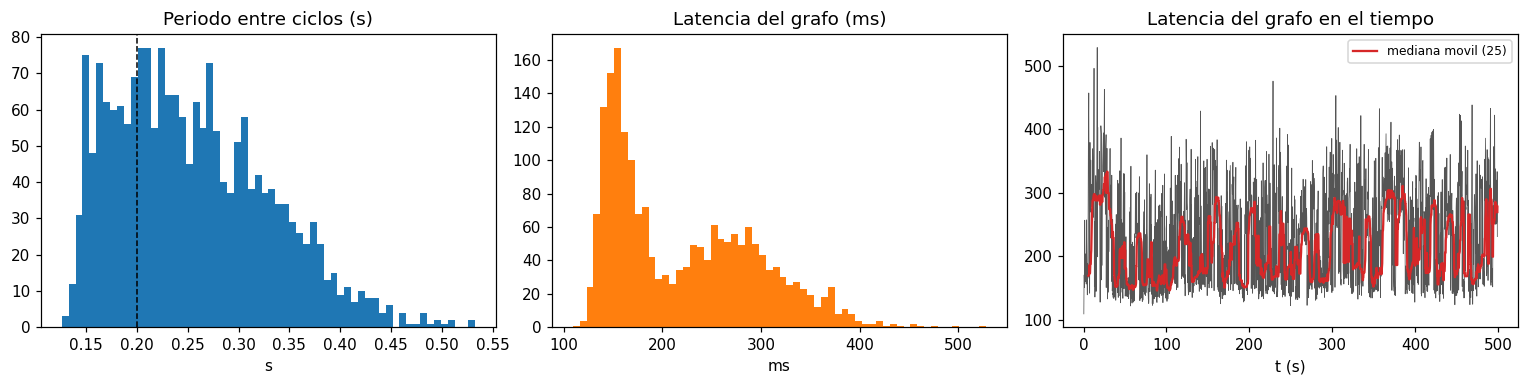

In [5]:
periodo = df['t'].diff().dropna()
lat = df['latency_graph_ms']
slm_lat = pd.to_numeric(df['slm_latency_ms'], errors='coerce').dropna()
resumen = pd.DataFrame({
    'periodo del lazo (s)': periodo.describe(percentiles=[.5, .95]),
    'latencia del grafo (ms)': lat.describe(percentiles=[.5, .95]),
    'latencia capa estrategica (ms)': slm_lat.describe(percentiles=[.5, .95]),
}).loc[['count', 'mean', '50%', '95%', 'max']].round(3)
display(resumen)
print(f'frecuencia efectiva: {1 / periodo.median():.2f} Hz (mediana); ciclos con periodo > 0.3 s: {(periodo > 0.3).mean():.1%}')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(periodo.clip(upper=0.8), bins=60, color='#1f77b4'); ax[0].axvline(0.2, color='k', ls='--', lw=1)
ax[0].set_title('Periodo entre ciclos (s)'); ax[0].set_xlabel('s')
ax[1].hist(lat, bins=60, color='#ff7f0e'); ax[1].set_title('Latencia del grafo (ms)'); ax[1].set_xlabel('ms')
ax[2].plot(df['t'], lat, lw=0.5, color='#555'); ax[2].plot(df['t'], lat.rolling(25).median(), color='#d62728', lw=1.5, label='mediana movil (25)')
ax[2].set_title('Latencia del grafo en el tiempo'); ax[2].set_xlabel('t (s)'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## §4 — Traza de decisión: ruta activa, waypoint y distancia al objetivo

`route` dice qué rama de `navigate` decidió el ciclo (NB3 §6): `reactive` (guiado nominal), `evasive` (evasión o maniobra comprometida), `girar_90` (muro de frente), `tactical` (escape de deadlock), `degraded` (sin AirSim). Abajo, la ruta por ciclo, el índice del objetivo activo y la distancia horizontal a ese objetivo. El índice incluye los puntos de paso del plan de ruta (`VIA_*`) y las sub-metas de la capa estratégica (`VLM_SUBGOAL`), que el tracker inserta delante del waypoint real.

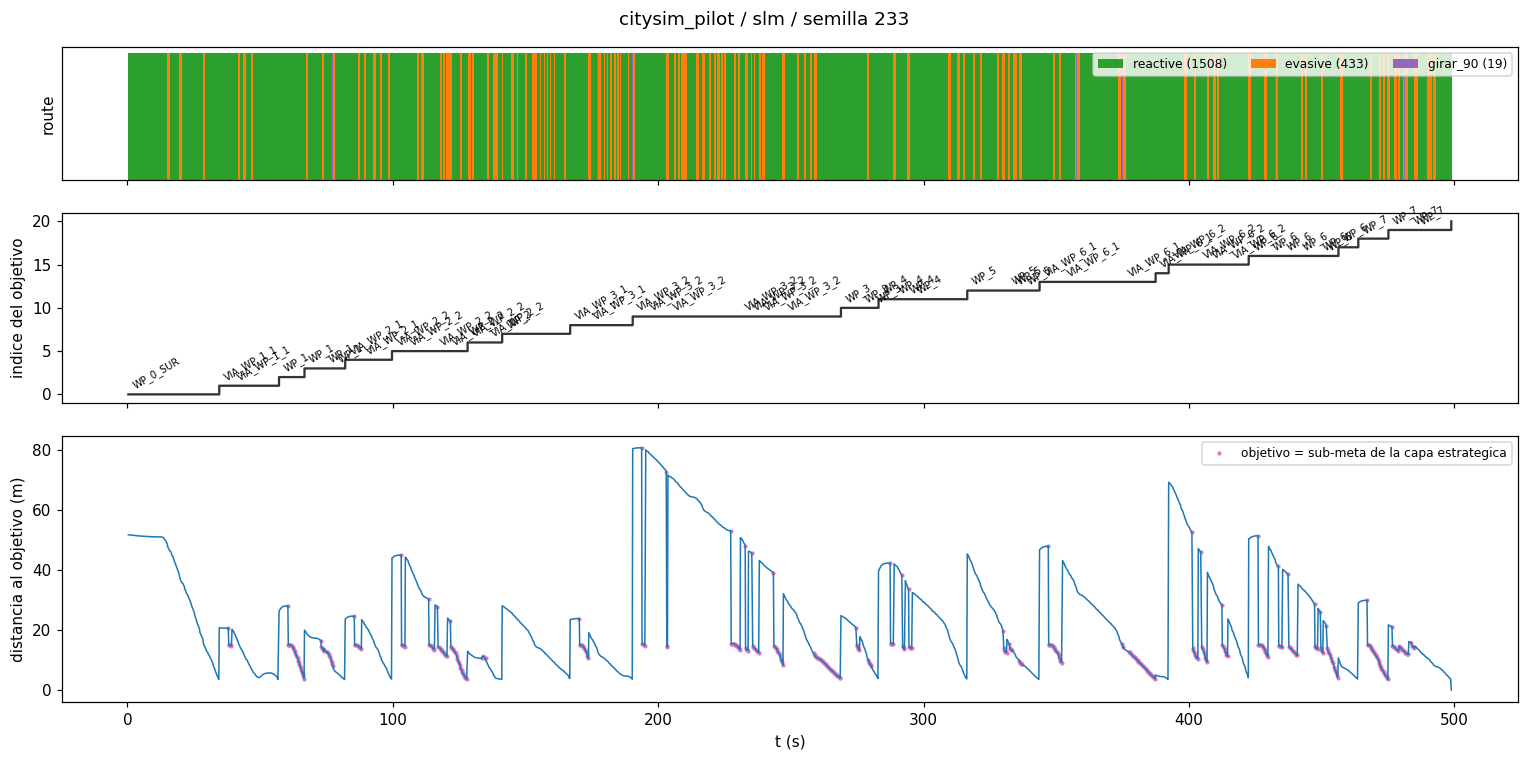

,ciclos
action,
MANTENER_RUMBO,1507
EVADIR_DERECHA,172
EVADIR_IZQUIERDA,166
GIRAR_90,114
FRENAR,1


In [6]:
COLORES = {'reactive': '#2ca02c', 'evasive': '#ff7f0e', 'girar_90': '#9467bd', 'tactical': '#d62728',
           'degraded': '#7f7f7f', 'deliberative': '#1f77b4', 'fsm': '#8c564b'}
fig, ax = plt.subplots(3, 1, figsize=(14, 7), sharex=True, gridspec_kw={'height_ratios': [0.7, 1, 1.4]})
t = df['t'].to_numpy()
dtc = np.r_[np.diff(t), 0.2]
for r, c in COLORES.items():
    m = (df['route'] == r).to_numpy()
    if m.any():
        ax[0].bar(t[m], 1, width=dtc[m], color=c, align='edge', label=f'{r} ({m.sum()})')
ax[0].set_yticks([]); ax[0].legend(ncol=6, fontsize=8, loc='upper right'); ax[0].set_ylabel('route')
ax[1].step(t, df['wp_index'], where='post', color='#333'); ax[1].set_ylabel('indice del objetivo')
lab = df['state.target_waypoint.label'].fillna('')
cambios = df.index[lab.ne(lab.shift())]
for i in cambios:
    if lab[i] and not lab[i].startswith('VLM'):
        ax[1].annotate(lab[i], (t[i], df['wp_index'][i]), fontsize=6.5, rotation=30, xytext=(2, 4), textcoords='offset points')
ax[2].plot(t, df['dist_to_wp_m'], color='#1f77b4', lw=1)
sub = lab.str.startswith('VLM')
ax[2].scatter(t[sub], df['dist_to_wp_m'][sub], s=3, color='#e377c2', label='objetivo = sub-meta de la capa estrategica')
ax[2].set_ylabel('distancia al objetivo (m)'); ax[2].set_xlabel('t (s)'); ax[2].legend(fontsize=8)
fig.suptitle(f"{summary['scenario']} / {summary['arm']} / semilla {summary['seed']}")
plt.tight_layout(); plt.show()
display(df['action'].value_counts().to_frame('ciclos'))

## §5 — El `ObstacleField` en el tiempo

La fuente del campo de cada ciclo dice cuánta evidencia tuvo el lazo rápido:

- `flow`: el estimador produjo un campo con este par de fotogramas.
- `holdover`: se sostuvo el último campo válido con el TTC decrementado, porque la rotación entre fotogramas superó `FLOW_MAX_ROTATION_DEG` o el FOE no fue confiable.
- `degraded`: rotación grande sin campo previo que sostener, o Δt inválido.
- `none`: sin par de fotogramas.

Abajo, la proporción de cada fuente, su relación con la velocidad de giro y las series por sector.

,ciclos,fraccion,|giro| mediano (deg/s)
field_source,,,
degraded,694,0.354,14.5
flow,751,0.383,3.3
holdover,514,0.262,10.2
none,1,0.001,0.0


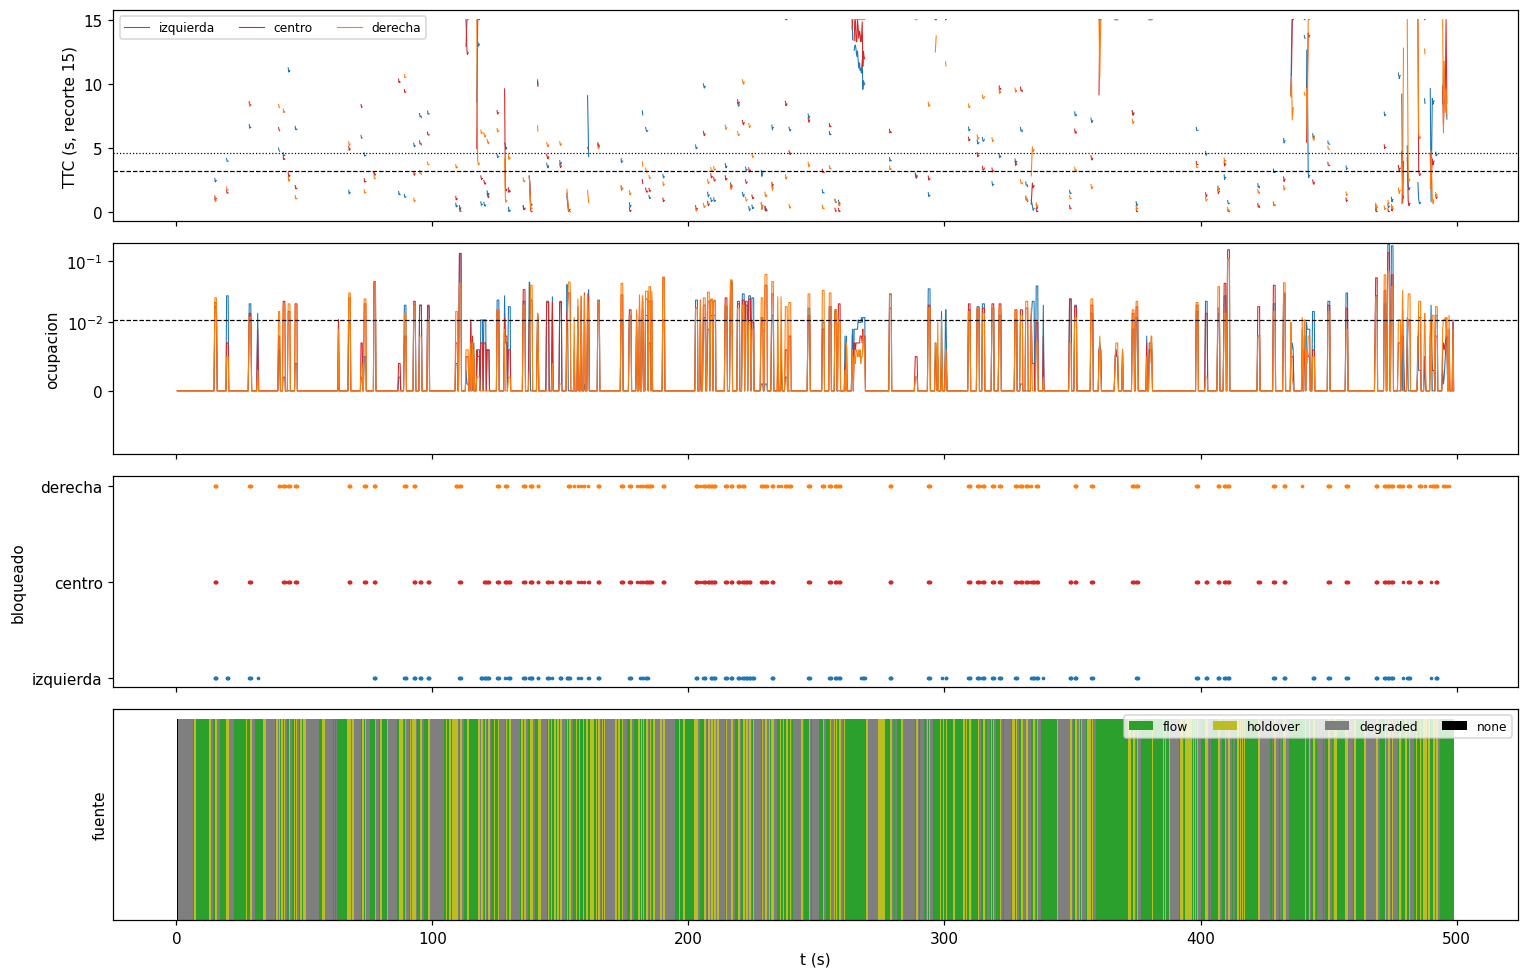

In [7]:
src = df['field_source'].fillna('none')
yaw_rate = np.degrees(np.unwrap(np.radians(df['yaw_deg'])))
yaw_rate = pd.Series(np.r_[0, np.diff(yaw_rate) / np.maximum(np.diff(t), 1e-3)])
tab = pd.DataFrame({'ciclos': src.value_counts(), 'fraccion': src.value_counts(normalize=True).round(3),
                    '|giro| mediano (deg/s)': yaw_rate.abs().groupby(src).median().round(1)})
display(tab)

fig, ax = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
SC = {'izquierda': '#1f77b4', 'centro': '#d62728', 'derecha': '#ff7f0e'}
for s_, c in SC.items():
    ttc = pd.to_numeric(df[f'field_{s_}_ttc_s'], errors='coerce')
    ax[0].plot(t, ttc.clip(upper=15), lw=0.7, color=c, label=s_)
    ax[1].plot(t, pd.to_numeric(df[f'field_{s_}_occ'], errors='coerce'), lw=0.7, color=c)
    bl = df[f'field_{s_}_blocked'].astype(str).str.lower().eq('true')
    ax[2].scatter(t[bl], np.full(bl.sum(), list(SC).index(s_)), s=2, color=c)
ax[0].axhline(3.2, color='k', ls='--', lw=0.8); ax[0].axhline(4.6, color='k', ls=':', lw=0.8)
ax[0].set_ylabel('TTC (s, recorte 15)'); ax[0].legend(ncol=3, fontsize=8)
ax[1].axhline(0.011, color='k', ls='--', lw=0.8); ax[1].set_ylabel('ocupacion'); ax[1].set_yscale('symlog', linthresh=0.01)
ax[2].set_yticks([0, 1, 2], list(SC)); ax[2].set_ylabel('bloqueado')
for k, (s_, c) in enumerate({'flow': '#2ca02c', 'holdover': '#bcbd22', 'degraded': '#7f7f7f', 'none': '#000'}.items()):
    m = (src == s_).to_numpy()
    ax[3].bar(t[m], 1, width=dtc[m], color=c, align='edge', label=s_)
ax[3].legend(ncol=4, fontsize=8); ax[3].set_yticks([]); ax[3].set_ylabel('fuente'); ax[3].set_xlabel('t (s)')
plt.tight_layout(); plt.show()

## §6 — La capa estratégica: consultas, respuesta y sub-metas

En la v4 la fuente de la capa estratégica es la profundidad monocular estimada (`STRATEGIC_SOURCE=depth`). Cada consulta envía el fotograma crudo (`photo-*.png`). La respuesta es el percentil 5 de la profundidad estimada en cada sector de la grilla 3×3 del recorte cuadrado (columnas A/B/C, filas 1/2/3). Un sector es «libre» si ese valor es ≥ 15 m. Con esa respuesta, `decide_subgoal()` elige el sector libre más cercano a la dirección de la meta y lo convierte en una sub-meta en coordenadas del mundo, anclada a la pose del instante de captura (NB4 §5). El CSV registra la respuesta cruda (`slm_raw_response`) y el resultado (`state._vlm_strategic.*`).

292 consultas; periodo medio entre consultas 1.15 s; latencia mediana 134 ms


,A1,B1,C1,A2,B2,C2,A3,B3,C3
fraccion de consultas con el sector libre (p5 >= 15 m),0.83,0.94,0.9,0.7,0.8,0.76,0.0,0.0,0.0


,consultas por resultado
state._vlm_strategic.outcome,
directo_libre,212
subgoal,77
sin_respuesta,9
sin_sector_libre,3


,sub-metas por sector elegido
state._vlm_strategic.subgoal.sector,
B2,29
C2,16
A2,12
C1,9
B1,6
A1,5


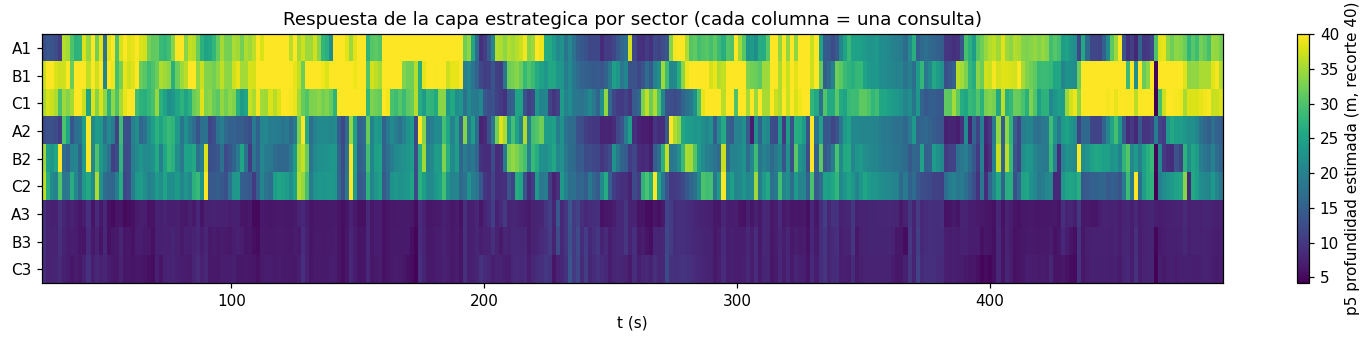

In [8]:
q = df[df['slm_invoked'].astype(str).str.lower() == 'true'].copy()
CELLS = [c + r for r in '123' for c in 'ABC']
p5 = []
for raw in q['slm_raw_response']:
    try:
        p5.append(json.loads(raw)['p5_m'][0])
    except Exception:
        p5.append({c: np.nan for c in CELLS})
P5 = pd.DataFrame(p5, index=q.index)[CELLS]
print(f'{len(q)} consultas; periodo medio entre consultas {q["t"].diff().median():.2f} s; latencia mediana {pd.to_numeric(q["slm_latency_ms"]).median():.0f} ms')
display((P5 >= 15).mean().to_frame('fraccion de consultas con el sector libre (p5 >= 15 m)').T.round(2))

oc = df['state._vlm_strategic.outcome'].fillna('-')
nuevas = df['state._vlm_strategic.anchor.ts'].ne(df['state._vlm_strategic.anchor.ts'].shift())
display(df.loc[nuevas, 'state._vlm_strategic.outcome'].value_counts().to_frame('consultas por resultado'))
display(df.loc[nuevas & (oc == 'subgoal'), 'state._vlm_strategic.subgoal.sector'].value_counts().to_frame('sub-metas por sector elegido'))

fig, ax = plt.subplots(figsize=(14, 3.2))
im = ax.imshow(P5.T.clip(upper=40).values, aspect='auto', cmap='viridis', interpolation='nearest',
               extent=[q['t'].iloc[0], q['t'].iloc[-1], 8.5, -0.5])
ax.set_yticks(range(9), CELLS); ax.set_xlabel('t (s)'); plt.colorbar(im, ax=ax, label='p5 profundidad estimada (m, recorte 40)')
ax.set_title('Respuesta de la capa estrategica por sector (cada columna = una consulta)')
plt.tight_layout(); plt.show()

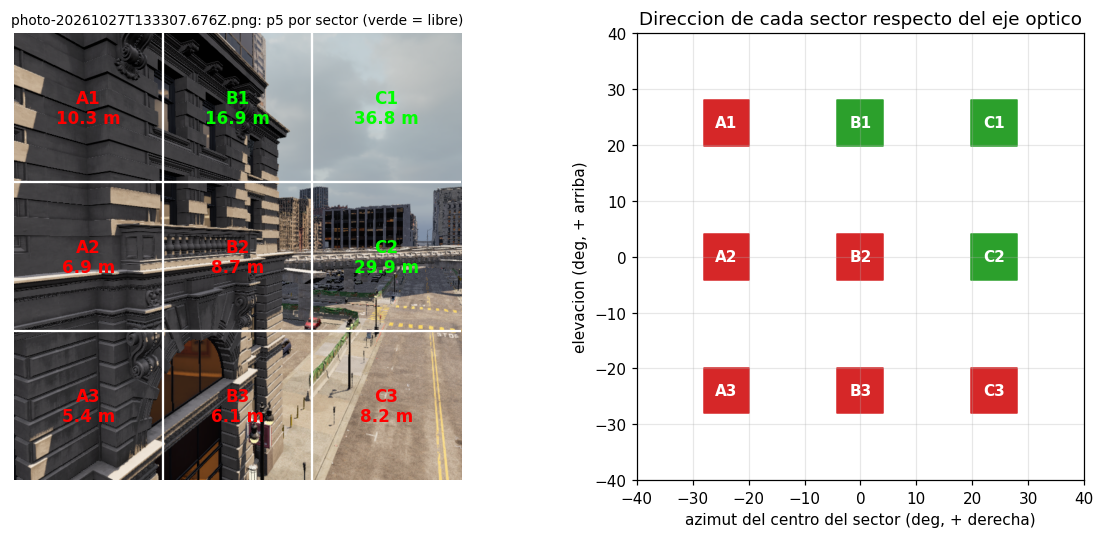

In [9]:
# Una consulta concreta: la foto enviada, la grilla y la respuesta.
# La foto guardada es el RECORTE CUADRADO (720 x 720) del fotograma de 1080 x 720; la focal es la del fotograma
# completo (90 deg de campo horizontal sobre 1080 px), como guarda el ancla en vuelo.
from src.agents.vlm_strategic import cell_centers_deg, _focal_px
assert len(fotos) == len(q), 'una foto por consulta'
mixtas = [k for k, i in enumerate(q.index) if 2 <= (P5.loc[i] >= 15).sum() <= 7]
k = mixtas[len(mixtas) // 2]
i, foto = q.index[k], fotos[k]
crop = cv2.cvtColor(cv2.imread(str(foto)), cv2.COLOR_BGR2RGB)
side, f = crop.shape[0], _focal_px(1080)
r = P5.loc[i]
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(crop)
for kk in (1, 2):
    ax[0].axvline(kk * side / 3, color='w'); ax[0].axhline(kk * side / 3, color='w')
for ci, c in enumerate('ABC'):
    for ri, rr in enumerate('123'):
        v = r[c + rr]
        ax[0].text((ci + .5) * side / 3, (ri + .5) * side / 3, f'{c}{rr}\n{v:.1f} m', color='lime' if v >= 15 else 'red',
                   ha='center', va='center', fontsize=11, weight='bold')
ax[0].set_title(f'{foto.name}: p5 por sector (verde = libre)', fontsize=9); ax[0].axis('off')
cc = cell_centers_deg(side, f)
ax[1].scatter([v[0] for v in cc.values()], [v[1] for v in cc.values()], s=900, c=['#2ca02c' if r[kk] >= 15 else '#d62728' for kk in cc], marker='s')
for kk, (az, el) in cc.items():
    ax[1].text(az, el, kk, ha='center', va='center', color='w', weight='bold')
ax[1].set_xlim(-40, 40); ax[1].set_ylim(-40, 40)
ax[1].set_xlabel('azimut del centro del sector (deg, + derecha)'); ax[1].set_ylabel('elevacion (deg, + arriba)')
ax[1].set_title('Direccion de cada sector respecto del eje optico'); ax[1].grid(alpha=.3); ax[1].set_aspect('equal')
plt.tight_layout(); plt.show()

## §7 — Atascos y gobernador de velocidad

El `StallDetector` publica dos contadores, que `navigate` convierte en deadlock (NB3 §6, regla 2):

- `_stopped_cycles`: ciclos con avance ordenado y sin desplazamiento medido. El umbral es `STOPPED_DELIBERATIVE_CYCLES`.
- `_wp_no_progress_cycles`: ciclos sin acercarse 2 m al objetivo actual. El umbral es `WP_NO_PROGRESS_THRESHOLD`.

El gobernador de velocidad (`state._speed_cap`) muestra cuándo se limitó el crucero por falta de evidencia o después de un frente bloqueado.

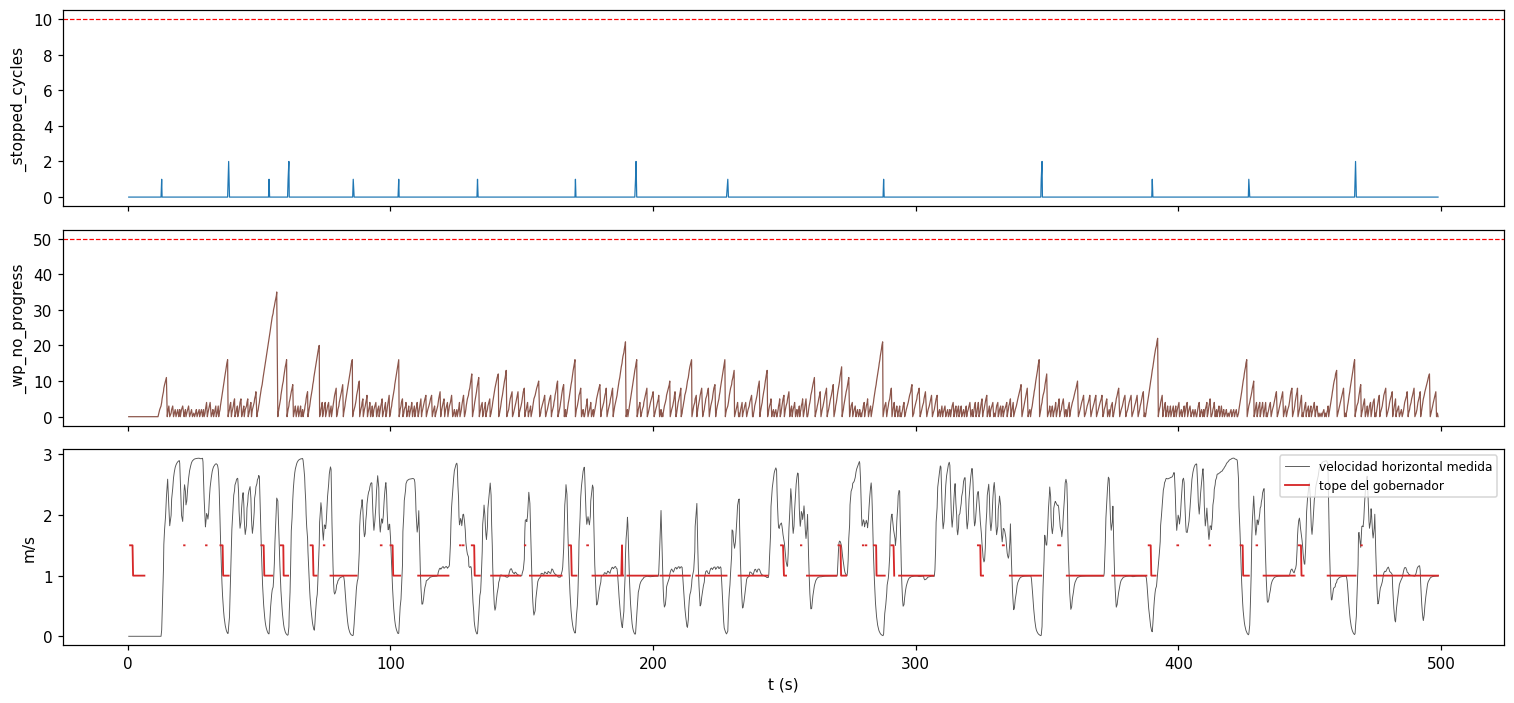

ciclos con tope del gobernador: 56.2%; deadlocks en el summary: 0; escapes verticales: 0; ciclos route=tactical: 0


In [10]:
stop_thr = int(os.getenv('STOPPED_DELIBERATIVE_CYCLES', '10')); prog_thr = int(os.getenv('WP_NO_PROGRESS_THRESHOLD', '50'))
fig, ax = plt.subplots(3, 1, figsize=(14, 6.5), sharex=True)
ax[0].plot(t, df['state._stopped_cycles'], lw=0.8); ax[0].axhline(stop_thr, color='r', ls='--', lw=0.8); ax[0].set_ylabel('_stopped_cycles')
ax[1].plot(t, df['state._wp_no_progress_cycles'], lw=0.8, color='#8c564b'); ax[1].axhline(prog_thr, color='r', ls='--', lw=0.8)
ax[1].set_ylabel('_wp_no_progress')
cap = pd.to_numeric(df['state._speed_cap'], errors='coerce')
v_xy = np.hypot(df['vel_x'], df['vel_y'])
ax[2].plot(t, v_xy, lw=0.6, color='#555', label='velocidad horizontal medida')
ax[2].plot(t, cap, lw=1.2, color='#d62728', label='tope del gobernador')
ax[2].set_ylabel('m/s'); ax[2].set_xlabel('t (s)'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"ciclos con tope del gobernador: {cap.notna().mean():.1%}; deadlocks en el summary: {summary['deadlock_events']}; "
      f"escapes verticales: {summary['vertical_escapes']}; ciclos route=tactical: {(df['route'] == 'tactical').sum()}")

## §8 — Trayectoria sobre el mapa cenital registrado

Los mapas de CitySim y TownSim (`citysim_ortho.png`, `townsim_ortho.png`) están registrados con el mundo de AirSim. El centro de la imagen es el origen NED, el norte está arriba y la escala es la de `map_scales.json`. Eso permite superponer:

- la trayectoria volada, coloreada por ruta activa;
- los waypoints del manifiesto y los puntos de paso (`VIA_*`) que agregó el plan de ruta con el VLM (NB4), leídos del manifiesto planificado del lote;
- las sub-metas de la capa estratégica;
- las muestras de la auditoría de distancia mínima, coloreadas por distancia.

MiniSim no tiene mapa registrado (es un plano sin obstáculos). En ese caso se dibuja sin fondo.

manifiesto: airsim-runs\produccion\v4\lote6_citysim_pilot\citysim_pilot\route_plan\citysim_pilot.json


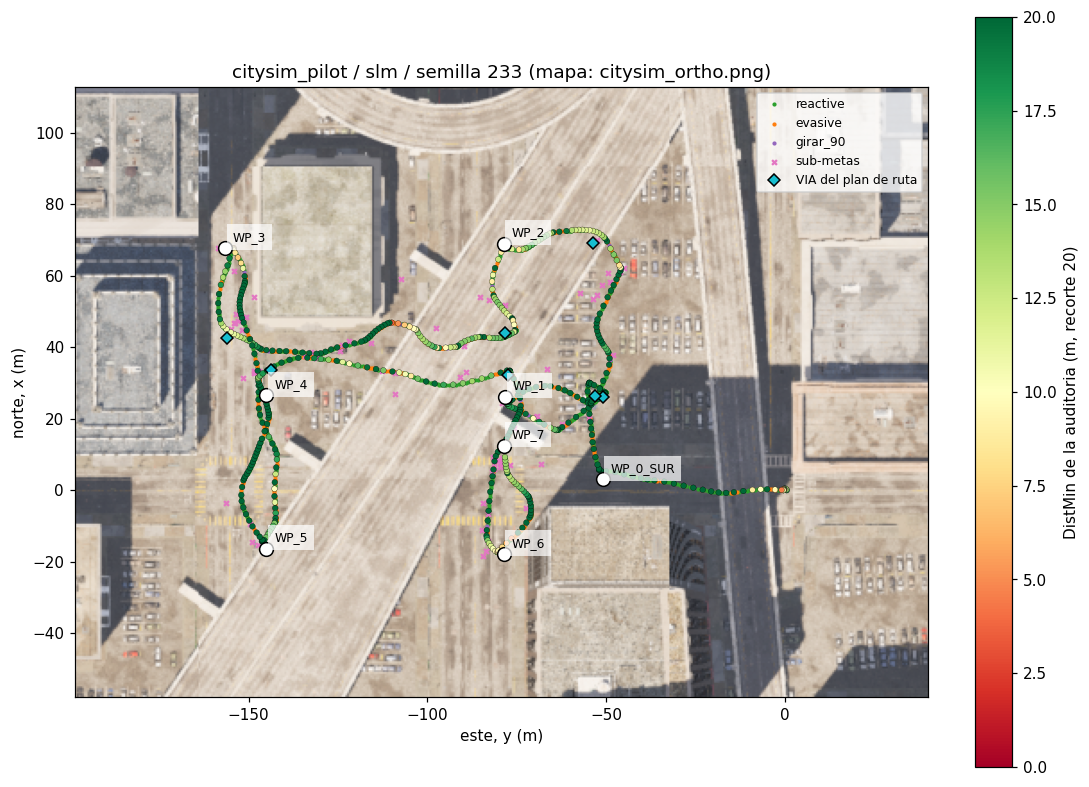

DistMin sin la primera muestra: 3.76 m en x=46.9, y=-110.0, z=-11.6


In [11]:
from src.planning.route_planner import MapView
manifest = json.loads((FLIGHTPLANS / f"{summary['scenario']}.json").read_text(encoding='utf-8'))
# Manifiesto planificado del lote (con los VIA del plan de ruta), si el lote volo con plan
plan_path = RUN_DIR.parents[2] / 'route_plan' / f"{summary['scenario']}.json"
planned = json.loads(plan_path.read_text(encoding='utf-8')) if plan_path.exists() else None
print('manifiesto:', plan_path.relative_to(ROOT) if planned else f"{summary['scenario']}.json (sin plan de ruta)")
wps = (planned or manifest)['waypoints']
mapa = manifest.get('map') if manifest.get('map') in ('citysim_ortho.png', 'townsim_ortho.png') else None

def dibujar_mapa(ax, xs, ys, margen=40):
    # Recorte del mapa registrado alrededor de (xs, ys) en NED; ejes: este (y) horizontal, norte (x) vertical.
    if mapa is None:
        return
    mv = MapView.load(mapa)
    x0, x1, y0, y1 = min(xs) - margen, max(xs) + margen, min(ys) - margen, max(ys) + margen
    u0, v0 = mv.to_px(x1, y0); u1, v1 = mv.to_px(x0, y1)
    u0, v0, u1, v1 = (int(max(0, round(a))) for a in (u0, v0, u1, v1))
    ax.imshow(cv2.cvtColor(mv.image[v0:v1, u0:u1], cv2.COLOR_BGR2RGB), extent=[y0, y1, x0, x1], alpha=0.9)

fig, ax = plt.subplots(figsize=(10, 10))
xs = list(df['pos_x']) + [w['x'] for w in wps]; ys = list(df['pos_y']) + [w['y'] for w in wps]
dibujar_mapa(ax, xs, ys)
for r, c in COLORES.items():
    m = df['route'] == r
    if m.any():
        ax.scatter(df.loc[m, 'pos_y'], df.loc[m, 'pos_x'], s=3, color=c, label=r)
for w in wps:
    via = w.get('planned_via')
    ax.plot(w['y'], w['x'], 'o' if not via else 'D', ms=9 if not via else 6, mfc='white' if not via else '#17becf', mec='k')
    if not via:
        ax.annotate(w['label'], (w['y'], w['x']), fontsize=8, xytext=(5, 5), textcoords='offset points', color='k',
                    bbox=dict(fc='white', alpha=0.7, lw=0))
sg = df[df['state._vlm_strategic.outcome'] == 'subgoal'].drop_duplicates('state._vlm_strategic.anchor.ts')
ax.scatter(sg['state._vlm_strategic.subgoal.y'], sg['state._vlm_strategic.subgoal.x'], s=10, marker='x', color='#e377c2', label='sub-metas')
sc = ax.scatter(dm['y'], dm['x'], c=dm['dist_m'].clip(upper=20), cmap='RdYlGn', s=14, vmin=0, vmax=20, edgecolor='k', lw=0.2)
plt.colorbar(sc, ax=ax, fraction=0.04, label='DistMin de la auditoria (m, recorte 20)')
ax.plot([], [], 'D', mfc='#17becf', mec='k', label='VIA del plan de ruta')
ax.set_xlabel('este, y (m)'); ax.set_ylabel('norte, x (m)'); ax.set_aspect('equal'); ax.legend(fontsize=8, loc='best')
ax.set_title(f"{summary['scenario']} / {summary['arm']} / semilla {summary['seed']} (mapa: {mapa})")
plt.tight_layout(); plt.show()
k = dm['dist_m'].iloc[1:].idxmin()
print(f"DistMin sin la primera muestra: {dm['dist_m'][k]:.2f} m en x={dm['x'][k]:.1f}, y={dm['y'][k]:.1f}, z={dm['z'][k]:.1f}")

## §9 — Desglose por waypoint

`summary_by_wp.csv` agrega ciclos y tiempo por objetivo activo (incluidos los `VIA_*`; una etiqueta se repite cuando el tracker inserta una sub-meta delante del mismo waypoint). Sirve para ubicar en qué tramo se pierde el tiempo.

,cycles,duration_s
wp_label,,
WP_0_SUR,120,34.08
VIA_WP_1_1,97,22.09
WP_1,109,24.54
VIA_WP_2_1,77,17.44
VIA_WP_2_2,168,41.02
WP_2,97,25.47
VIA_WP_3_1,97,23.40
VIA_WP_3_2,314,78.20
WP_3,59,13.94


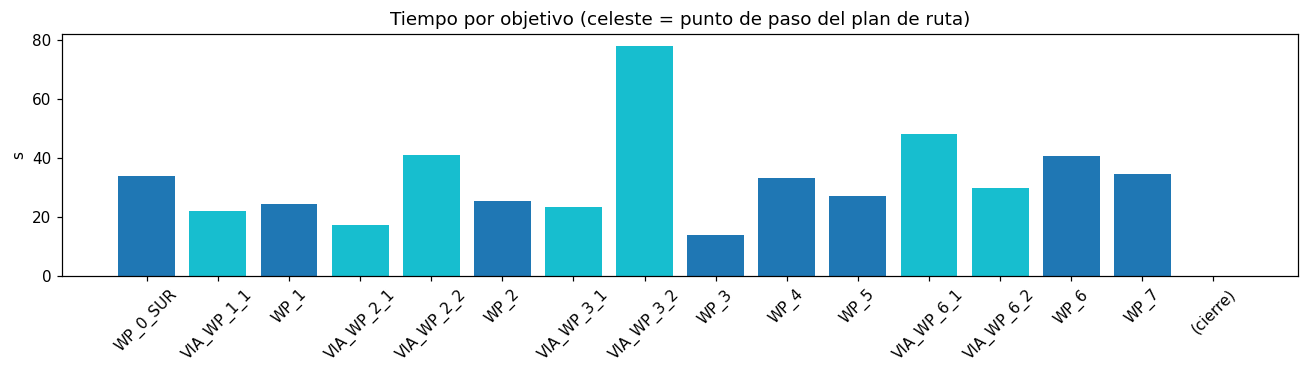

In [12]:
wp = pd.read_csv(f'{STEM}.summary_by_wp.csv')
wp['wp_label'] = wp['wp_label'].fillna('(cierre)')
por_tramo = wp.groupby('wp_label', sort=False)[['cycles', 'duration_s']].sum()
display(por_tramo)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(por_tramo.index, por_tramo['duration_s'], color=['#17becf' if l.startswith('VIA') else '#1f77b4' for l in por_tramo.index])
ax.set_ylabel('s'); ax.set_title('Tiempo por objetivo (celeste = punto de paso del plan de ruta)'); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

## §10 — La misma semilla volada por los cuatro brazos

La semilla fija el *jitter* de arranque (informe §10.4), así que las cuatro celdas de un lote con la misma semilla arrancan igual. Las trayectorias juntas muestran dónde se separan los comportamientos.

,celda,exito,duracion (s),recorrido (m),deadlocks,escapes verticales,rutas (% de ciclos)
0,fsm x blind,True,566.78,795.10,0,0,"fsm 98, reactive 2"
1,fsm x depth,False,440.35,474.07,18,0,"fsm 98, reactive 2"
2,reactive,True,320.74,641.00,0,0,reactive 100
3,slm x depth,True,499.06,675.36,0,0,"reactive 77, evasive 22, girar_90 1"


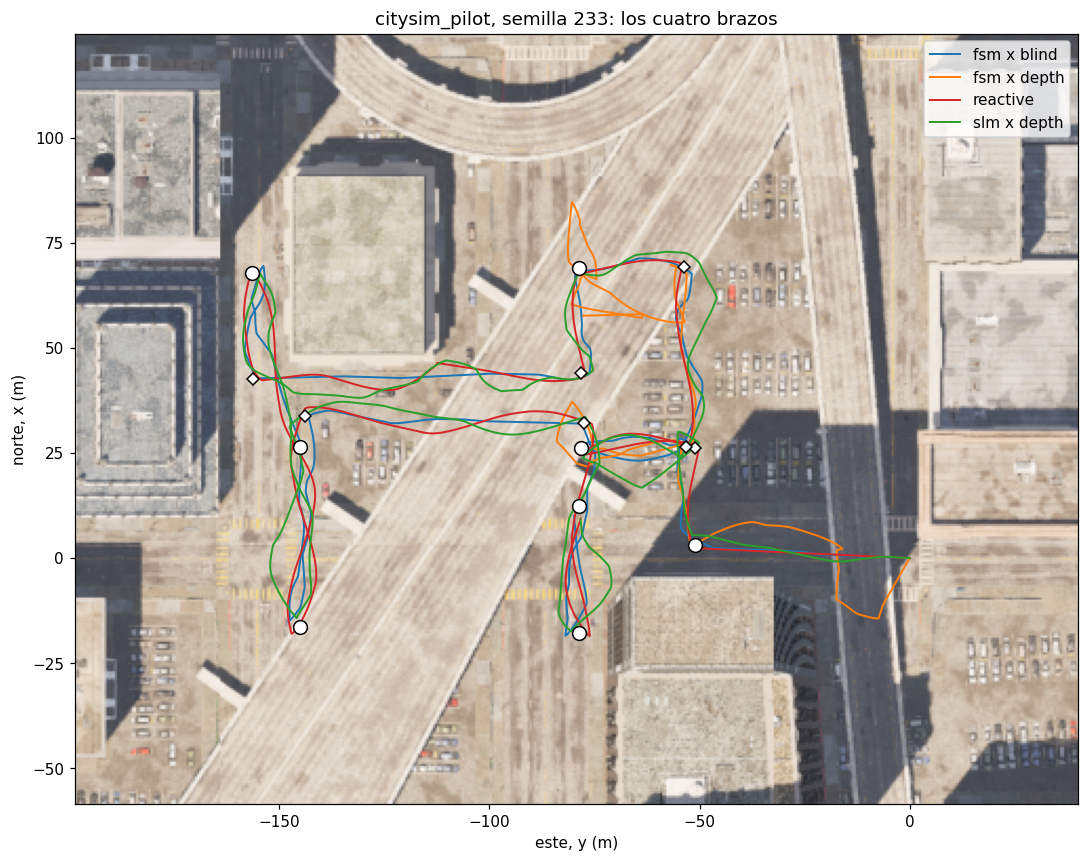

In [13]:
escenario_dir = RUN_DIR.parents[2]
seed = summary['seed']
otras = sorted(escenario_dir.glob(f'*/*/seed_{seed}_*'))
filas, trazas = [], {}
for d in otras:
    s = json.loads((d / f'{d.name}.summary.json').read_text(encoding='utf-8'))
    celda = 'reactive' if s['arm'] == 'reactive' else f"{s['arm']} x {s['deadlock_strategy']}"
    c = pd.read_csv(d / f'{d.name}.csv', usecols=['t', 'pos_x', 'pos_y', 'route'], low_memory=False)
    trazas[celda] = c
    rutas = c['route'].value_counts(normalize=True)
    filas.append({'celda': celda, 'exito': s['success'], 'duracion (s)': s['duration_s'], 'recorrido (m)': s['path_length_m'],
                  'deadlocks': s['deadlock_events'], 'escapes verticales': s.get('vertical_escapes'),
                  'rutas (% de ciclos)': ', '.join(f'{k} {100 * v:.0f}' for k, v in rutas.items())})
display(pd.DataFrame(filas))

fig, ax = plt.subplots(figsize=(10, 10))
dibujar_mapa(ax, [v for c in trazas.values() for v in c['pos_x']] + [w['x'] for w in wps],
             [v for c in trazas.values() for v in c['pos_y']] + [w['y'] for w in wps])
for (celda, c), col in zip(trazas.items(), ['#1f77b4', '#ff7f0e', '#d62728', '#2ca02c']):
    ax.plot(c['pos_y'], c['pos_x'], lw=1.3, color=col, label=celda)
for w in wps:
    ax.plot(w['y'], w['x'], 'D' if w.get('planned_via') else 'o', mfc='white', mec='k', ms=6 if w.get('planned_via') else 9)
ax.set_aspect('equal'); ax.legend(); ax.set_xlabel('este, y (m)'); ax.set_ylabel('norte, x (m)')
ax.set_title(f"{summary['scenario']}, semilla {seed}: los cuatro brazos")
plt.tight_layout(); plt.show()